# Dzień 2 — Ćwiczenia: under- i oversampling
### 🔑 WERSJA Z ROZWIĄZANIAMI — wszystkie TODO uzupełnione, uwaga nie jest to jedyne możliwe rozwiązanie
### Materiał towarzyszący prezentacji *„Metody na poziomie danych: under- i oversampling"*

**Plan:**
1. Wybór zbioru danych (syntetyczny albo prawdziwy ULB Credit Card Fraud)
2. Random Undersampling (RUS)
3. Random Oversampling (ROS)
4. SMOTE **od podstaw** — krok po kroku, dokładnie według wzoru z wykładu
5. Bonus: Tomek Links — czyszczenie granicy decyzyjnej
6. Porównanie wszystkich metod na tym samym zbiorze testowym


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (7, 4.5)

## Wybór zbioru danych

Dwie opcje — obie kończą się tymi samymi czterema obiektami, których używa reszta notatnika:
`X_train`, `X_test`, `y_train`, `y_test`.

1. **Syntetyczny** — ten sam sposób generowania co w Dniu 1 (~2,5% oszustw), nie wymaga internetu,
   wyniki bezpośrednio porównywalne z poprzednimi zajęciami.
2. **Prawdziwy** — zbiór ULB Credit Card Fraud (284 807 transakcji, ~0,17% oszustw — najbardziej
   ekstremalny przykład z Case Study 1), pobierany na żywo z OpenML. Wymaga dostępu do internetu z
   poziomu tego notatnika.

Uruchom **obie** komórki konfiguracyjne poniżej — każda przechowuje swoje dane niezależnie — a następnie
użyj przełącznika na końcu tej sekcji, aby wybrać, którego zbioru używa reszta notatnika.

### Opcja 1 — zbiór syntetyczny (ten sam kształt co w Dniu 1)

In [2]:
N_SAMPLES = 20000
FRAUD_RATE = 0.025

X_synth, y_synth = make_classification(
    n_samples=N_SAMPLES, n_features=10, n_informative=6, n_redundant=2,
    n_clusters_per_class=2, weights=[1 - FRAUD_RATE, FRAUD_RATE],
    flip_y=0.01, class_sep=0.9, random_state=RANDOM_STATE,
)
synth_feature_names = [
    "amount_zscore", "time_since_last_txn", "merchant_risk_score", "txn_velocity_1h",
    "avg_amount_7d_ratio", "distance_from_home", "device_trust_score", "account_age_days_z",
    "num_txn_today", "cross_border_flag",
]
synth_df = pd.DataFrame(X_synth, columns=synth_feature_names)
synth_df["is_fraud"] = y_synth

X_train_synth, X_test_synth, y_train_synth, y_test_synth = train_test_split(
    synth_df[synth_feature_names], synth_df["is_fraud"], test_size=0.25,
    stratify=synth_df["is_fraud"], random_state=RANDOM_STATE,
)
print(f"[syntetyczny] Train: {len(X_train_synth)} wierszy, {y_train_synth.mean()*100:.2f}% oszustw")
print(f"[syntetyczny] Test:  {len(X_test_synth)} wierszy, {y_test_synth.mean()*100:.2f}% oszustw")

[syntetyczny] Train: 15000 wierszy, 3.01% oszustw
[syntetyczny] Test:  5000 wierszy, 3.00% oszustw


### Opcja 2 — dane prawdziwe: ULB Credit Card Fraud, przez OpenML

Zbiór publiczny, nie wymaga konta Kaggle ani klucza API. Jeśli środowisko tego notatnika nie ma dostępu
do internetu, poniższa komórka zakończy się błędem w kontrolowany sposób, a Opcja 1 (syntetyczna)
pozostanie dostępna.

In [3]:
real_stats = []
ulb_df = None

# ULB Credit Card Fraud, przez OpenML (publiczny, bez danych uwierzytelniających)
try:
    from sklearn.datasets import fetch_openml

    ulb = fetch_openml(name="creditcard", version=1, as_frame=True, parser="auto")
    ulb_df = ulb.frame
    fraud_col = "Class" if "Class" in ulb_df.columns else ulb_df.columns[-1]
    n_rows = len(ulb_df)
    fraud_rate = ulb_df[fraud_col].astype(int).mean() * 100
    real_stats.append({"dataset": "ULB Credit Card", "n_rows_actual": n_rows, "fraud_rate_pct_actual": round(fraud_rate, 3)})
    print(f"ULB Credit Card: {n_rows:,} wierszy, {fraud_rate:.3f}% oszustw (pobrano przez OpenML)")
except Exception as e:
    print(f"Nie udało się pobrać ULB Credit Card przez OpenML: {e}")
    print("Jeśli to błąd sieci/proxy, spróbuj ponownie w środowisku z pełnym dostępem do internetu.")
    print("Opcja 1 (syntetyczna) jest nadal dostępna poniżej.")

Nie udało się pobrać ULB Credit Card przez OpenML: fetch_openml() got an unexpected keyword argument 'parser'
Jeśli to błąd sieci/proxy, spróbuj ponownie w środowisku z pełnym dostępem do internetu.
Opcja 1 (syntetyczna) jest nadal dostępna poniżej.


In [4]:
if ulb_df is not None:
    real_target_col = "Class" if "Class" in ulb_df.columns else ulb_df.columns[-1]
    real_feature_names = [c for c in ulb_df.columns if c != real_target_col]

    X_train_real, X_test_real, y_train_real, y_test_real = train_test_split(
        ulb_df[real_feature_names], ulb_df[real_target_col].astype(int), test_size=0.25,
        stratify=ulb_df[real_target_col], random_state=RANDOM_STATE,
    )
    print(f"[prawdziwy] Train: {len(X_train_real)} wierszy, {y_train_real.mean()*100:.3f}% oszustw")
    print(f"[prawdziwy] Test:  {len(X_test_real)} wierszy, {y_test_real.mean()*100:.3f}% oszustw")
    print("Uwaga: prawdziwy udział oszustw ULB (~0,17%) jest znacznie bardziej ekstremalny niż syntetyczne 2,5%")
    print("— spodziewaj się, że każda metoda poniżej zachowa się inaczej. SMOTE w Części 4 może też działać")
    print("wyraźnie wolniej na większym, prawdziwym zbiorze treningowym.")
else:
    print("Prawdziwy zbiór niedostępny w tym środowisku — użyj Opcji 1 (syntetyczny) poniżej.")

Prawdziwy zbiór niedostępny w tym środowisku — użyj Opcji 1 (syntetyczny) poniżej.


### Dokonaj wyboru

Ustaw `USE_REAL_DATA = True`, aby użyć prawdziwego zbioru ULB (jeśli pobieranie powyżej się powiodło),
albo zostaw `False`, aby użyć zbioru syntetycznego. Od tego miejsca cały notatnik odwołuje się wyłącznie
do `X_train` / `X_test` / `y_train` / `y_test` / `feature_names` — niezależnie od wybranego źródła.

In [5]:
USE_REAL_DATA = False  # <-- ustaw na True, aby użyć prawdziwego zbioru ULB, jeśli jest dostępny

if USE_REAL_DATA and ulb_df is not None:
    X_train, X_test, y_train, y_test = X_train_real, X_test_real, y_train_real, y_test_real
    feature_names = real_feature_names
    print(f"Używam danych PRAWDZIWYCH: {len(X_train)} wierszy treningowych, {y_train.mean()*100:.3f}% oszustw")
else:
    X_train, X_test, y_train, y_test = X_train_synth, X_test_synth, y_train_synth, y_test_synth
    feature_names = synth_feature_names
    print(f"Używam danych SYNTETYCZNYCH: {len(X_train)} wierszy treningowych, {y_train.mean()*100:.2f}% oszustw")

Używam danych SYNTETYCZNYCH: 15000 wierszy treningowych, 3.01% oszustw


## Część 1 — Random Undersampling (RUS)

Zachowujemy wszystkie wiersze z oszustwami i losowo zmniejszamy liczbę wierszy legalnych, aż osiągniemy
zadaną proporcję `ratio` (legalne : oszustwa). Jak zawsze — **resamplingowi poddajemy wyłącznie zbiór
treningowy.** `X_test` / `y_test` pozostają nietknięte przez cały notatnik.

### ROZWIĄZANIE — 1 — zaimplementuj random undersampling

Uzupełnij funkcję tak, aby:
1. zachowywała wszystkie indeksy klasy mniejszościowej (oszustwa),
2. losowo wybierała `n_legit_target = len(oszustwa) * ratio` indeksów klasy większościowej (bez zwracania),
3. zwracała połączony, przetasowany podzbiór `X`, `y`.

Wskazówka: `rng.choice(legit_idx, size=..., replace=False)`.

In [6]:
def losowy_undersampling(X, y, ratio=1.0, random_state=42):
    """Zachowuje wszystkie przykłady klasy mniejszościowej (1) i losowo zmniejsza
    liczbę przykładów klasy większościowej (0) do `ratio` razy tyle."""
    rng = np.random.RandomState(random_state)
    fraud_idx = y[y == 1].index.to_numpy()
    legit_idx = y[y == 0].index.to_numpy()

    # ROZWIĄZANIE —: ile przykładów legalnych chcemy zachować?
    n_legit_target = min(int(len(fraud_idx) * ratio), len(legit_idx))

    # ROZWIĄZANIE —: wylosuj n_legit_target indeksów spośród legit_idx, bez zwracania
    legit_keep = rng.choice(legit_idx, size=n_legit_target, replace=False)

    keep_idx = np.concatenate([fraud_idx, legit_keep])
    rng.shuffle(keep_idx)
    return X.loc[keep_idx], y.loc[keep_idx]


X_under, y_under = losowy_undersampling(X_train, y_train, ratio=1.0, random_state=RANDOM_STATE)
print("Przed resamplingiem:", y_train.value_counts().to_dict())
print("RUS -> 1:1:         ", y_under.value_counts().to_dict())

Przed resamplingiem: {0: 14549, 1: 451}
RUS -> 1:1:          {0: 451, 1: 451}


**Sprawdź się:** zmień `ratio` na `5.0` (łagodniejszy undersampling, proporcja 5:1 zamiast 1:1,
dokładnie jak na slajdzie z przykładem liczbowym) i porównaj, ile wierszy legalnych zostaje zachowanych.

In [7]:
X_under_5to1, y_under_5to1 = losowy_undersampling(X_train, y_train, ratio=5.0, random_state=RANDOM_STATE)
print("RUS -> 5:1:", y_under_5to1.value_counts().to_dict())

RUS -> 5:1: {0: 2255, 1: 451}


## Część 2 — Random Oversampling (ROS)

Tym razem zachowujemy wszystkie wiersze legalne i powielamy (ze zwracaniem) wiersze z oszustwami, aż
osiągniemy zadaną proporcję.

### ROZWIĄZANIE — 2 — zaimplementuj random oversampling

Uzupełnij funkcję tak, aby:
1. zachowywała wszystkie indeksy klasy większościowej (legalne),
2. losowo wybierała (ze zwracaniem!) `n_fraud_target = len(legalne) / ratio` indeksów klasy mniejszościowej,
3. zwracała połączony, przetasowany podzbiór `X`, `y`.

Wskazówka: `rng.choice(fraud_idx, size=..., replace=True)` — tym razem **ze zwracaniem**, bo duplikujemy.

In [8]:
def losowy_oversampling(X, y, ratio=1.0, random_state=42):
    """Zachowuje wszystkie przykłady klasy większościowej (0) i powiela (ze zwracaniem)
    przykłady klasy mniejszościowej (1), aż osiągną `ratio` razy mniej niż klasa większościowa."""
    rng = np.random.RandomState(random_state)
    fraud_idx = y[y == 1].index.to_numpy()
    legit_idx = y[y == 0].index.to_numpy()

    # ROZWIĄZANIE —: ile przykładów oszustwa potrzebujemy (po powieleniu)?
    n_fraud_target = int(len(legit_idx) / ratio)

    # ROZWIĄZANIE —: wylosuj n_fraud_target indeksów spośród fraud_idx, ZE zwracaniem
    fraud_resampled = rng.choice(fraud_idx, size=n_fraud_target, replace=True)

    keep_idx = np.concatenate([legit_idx, fraud_resampled])
    rng.shuffle(keep_idx)
    return X.loc[keep_idx], y.loc[keep_idx]


X_over, y_over = losowy_oversampling(X_train, y_train, ratio=1.0, random_state=RANDOM_STATE)
print("Przed resamplingiem:", y_train.value_counts().to_dict())
print("ROS -> 1:1:         ", y_over.value_counts().to_dict())

Przed resamplingiem: {0: 14549, 1: 451}
ROS -> 1:1:          {0: 14549, 1: 14549}


## Część 3 — SMOTE od podstaw

Pakiet `imbalanced-learn` (funkcja `SMOTE`) może nie być dostępny w każdym środowisku — a budując
algorytm samodzielnie, naprawdę widać, co robi biblioteka „pod maską". Implementujemy dokładnie te same
5 kroków, co na slajdzie „SMOTE, krok po kroku":

1. Wybierz prawdziwy punkt mniejszościowy xᵢ.
2. Znajdź jego k najbliższych sąsiadów tej samej klasy.
3. Wylosuj jednego sąsiada x̂ᵢ spośród tych k.
4. Interpoluj: `x_new = x_i + u · (x̂_i − x_i)`, gdzie `u ~ Uniform(0, 1)`.
5. Powtórz, aż osiągniesz zadaną liczbę nowych punktów.

**Przykład liczbowy (ten sam co na slajdzie):** xᵢ = (2,0; 5,0), x̂ᵢ = (4,0; 1,0), u = 0,3
→ x_new = (2,0 + 0,3·2,0; 5,0 + 0,3·(−4,0)) = (2,6; 3,8).

### ROZWIĄZANIE — 3 — zaimplementuj SMOTE

Uzupełnij pętlę generującą syntetyczne punkty. `indices[i]` to indeksy k+1 najbliższych sąsiadów punktu
`i` (łącznie z nim samym na pozycji 0 — stąd `[1:]` poniżej, żeby go pominąć).

In [9]:
def smote_od_podstaw(X_minority, n_syntetycznych, k=5, random_state=42):
    """Generuje `n_syntetycznych` nowych punktów klasy mniejszościowej metodą SMOTE."""
    rng = np.random.RandomState(random_state)
    X_min = X_minority.values
    n_min = len(X_min)

    nn = NearestNeighbors(n_neighbors=min(k + 1, n_min)).fit(X_min)
    _, indices = nn.kneighbors(X_min)

    synthetic = []
    for _ in range(n_syntetycznych):
        # ROZWIĄZANIE — krok 1: wylosuj indeks i prawdziwego punktu mniejszościowego (0 <= i < n_min)
        i = rng.randint(0, n_min)

        # krok 2: k najbliższych sąsiadów punktu i (bez niego samego)
        sasiedzi = indices[i][1:]

        # ROZWIĄZANIE — krok 3: wylosuj jednego sąsiada j spośród `sasiedzi`
        j = rng.choice(sasiedzi)

        x_i = X_min[i]
        x_hat_i = X_min[j]

        # ROZWIĄZANIE — krok 4: wylosuj u z rozkładu jednostajnego Uniform(0, 1) i wyznacz x_new
        u = rng.uniform(0, 1)
        x_new = x_i + u * (x_hat_i - x_i)

        synthetic.append(x_new)
    return np.array(synthetic)


X_train_fraud = X_train[y_train == 1]
X_train_legit = X_train[y_train == 0]
n_potrzebnych = len(X_train_legit) - len(X_train_fraud)  # ile nowych punktów, by osiągnąć 1:1

synth = smote_od_podstaw(X_train_fraud, n_potrzebnych, k=5, random_state=RANDOM_STATE)

X_smote = pd.concat([
    X_train_legit,
    X_train_fraud,
    pd.DataFrame(synth, columns=feature_names),
], ignore_index=True)
y_smote = pd.Series([0] * len(X_train_legit) + [1] * len(X_train_fraud) + [1] * len(synth))

print("Przed resamplingiem:", y_train.value_counts().to_dict())
print("SMOTE -> 1:1:       ", y_smote.value_counts().to_dict())
print(f"\n{len(synth)} nowych, syntetycznych punktów — żaden z nich nie jest kopią istniejącego wiersza.")

Przed resamplingiem: {0: 14549, 1: 451}
SMOTE -> 1:1:        {0: 14549, 1: 14549}

14098 nowych, syntetycznych punktów — żaden z nich nie jest kopią istniejącego wiersza.


**Sprawdź się:** porównaj pierwszy wygenerowany punkt syntetyczny z prawdziwym punktem mniejszościowym,
z którego powstał — powinny być blisko siebie, ale nie identyczne.

In [10]:
print("Przykładowy syntetyczny punkt:", np.round(synth[0], 3))
print("Najbliższy mu prawdziwy punkt mniejszościowy w zbiorze treningowym:")
odleglosci = np.linalg.norm(X_train_fraud.values - synth[0], axis=1)
print(np.round(X_train_fraud.values[np.argmin(odleglosci)], 3))

Przykładowy syntetyczny punkt: [-2.742  1.716 -0.934 -2.253  1.182  0.182  0.689  0.875 -1.626  0.979]
Najbliższy mu prawdziwy punkt mniejszościowy w zbiorze treningowym:
[-2.689  1.626 -0.912 -2.283  1.195  0.143  0.615  0.855 -1.611  0.898]


## Część 4 — Bonus: Tomek Links

Tomek Link to para punktów z przeciwnych klas będących wzajemnie swoimi najbliższymi sąsiadami. W
przeciwieństwie do RUS, Tomek Links nie dąży do żadnej konkretnej proporcji — usuwa tylko punkty
większościowe leżące dokładnie na granicy decyzyjnej, czyszcząc ją, zamiast wyrównywać liczebności klas.

To ćwiczenie jest opcjonalne — jeśli brakuje czasu, przejdź od razu do Części 5.

### ROZWIĄZANIE — 4 (bonus) — znajdź pary Tomek Link

Dla każdego punktu znajdujemy jego najbliższego sąsiada (`nearest[i]`). Para (i, j) jest Tomek Linkiem,
gdy są **wzajemnie** najbliższymi sąsiadami (`nearest[j] == i`) **i** należą do różnych klas.

In [11]:
def znajdz_tomek_links(X, y):
    """Zwraca posortowaną listę indeksów punktów WIĘKSZOŚCIOWYCH do usunięcia."""
    nn = NearestNeighbors(n_neighbors=2).fit(X.values)
    _, idx = nn.kneighbors(X.values)
    y_arr = y.to_numpy()
    nearest = idx[:, 1]  # najbliższy sąsiad każdego punktu (pomijając siebie samego)

    do_usuniecia = []
    for i in range(len(X)):
        j = nearest[i]
        # ROZWIĄZANIE —: sprawdź, czy (i, j) to Tomek Link — wzajemni najbliżsi sąsiedzi RÓŻNYCH klas
        czy_tomek_link = (nearest[j] == i) and (y_arr[i] != y_arr[j])
        if czy_tomek_link:
            punkt_wiekszosciowy = i if y_arr[i] == 0 else j
            do_usuniecia.append(punkt_wiekszosciowy)
    return sorted(set(do_usuniecia))


# Na próbce 3000 wierszy (dla szybkości — na pełnym zbiorze też zadziała, tylko wolniej)
probka_idx = X_train.sample(3000, random_state=RANDOM_STATE).index
X_probka = X_train.loc[probka_idx].reset_index(drop=True)
y_probka = y_train.loc[probka_idx].reset_index(drop=True)

do_usuniecia = znajdz_tomek_links(X_probka, y_probka)
print(f"Znaleziono {len(do_usuniecia)} punktów większościowych tworzących Tomek Link (na próbce 3000 wierszy).")
print("Są to transakcje legalne leżące najbliżej granicy z klasą oszustw — kandydaci do usunięcia.")

Znaleziono 20 punktów większościowych tworzących Tomek Link (na próbce 3000 wierszy).
Są to transakcje legalne leżące najbliżej granicy z klasą oszustw — kandydaci do usunięcia.


## Część 5 — Porównanie wszystkich metod

Ten sam klasyfikator (Logistic Regression, bez żadnego ważenia klas), wytrenowany na czterech różnych
wersjach zbioru treningowego, oceniony na tym samym, nietkniętym zbiorze testowym.

In [12]:
wyniki = []
for nazwa, (Xr, yr) in {
    "Oryginalny (bez resamplingu)": (X_train, y_train),
    "RUS -> 1:1": (X_under, y_under),
    "ROS -> 1:1": (X_over, y_over),
    "SMOTE -> 1:1": (X_smote, y_smote),
}.items():
    clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    clf.fit(Xr, yr)
    proba = clf.predict_proba(X_test)[:, 1]
    preds = (proba >= 0.5).astype(int)
    wyniki.append({
        "metoda": nazwa,
        "precision": precision_score(y_test, preds, zero_division=0),
        "recall": recall_score(y_test, preds, zero_division=0),
        "f1": f1_score(y_test, preds, zero_division=0),
        "pr_auc": average_precision_score(y_test, proba),
    })

wyniki_df = pd.DataFrame(wyniki).round(3)
wyniki_df

,metoda,precision,recall,f1,pr_auc
0,Oryginalny (bez resamplingu),0.925,0.247,0.389,0.510
1,RUS -> 1:1,0.095,0.787,0.170,0.402
2,ROS -> 1:1,0.100,0.760,0.177,0.451
3,SMOTE -> 1:1,0.103,0.760,0.181,0.464


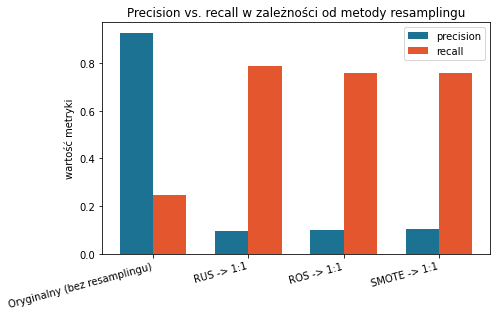

In [13]:
fig, ax = plt.subplots()
x = np.arange(len(wyniki_df))
width = 0.35
ax.bar(x - width/2, wyniki_df["precision"], width, label="precision", color="#1C7293")
ax.bar(x + width/2, wyniki_df["recall"], width, label="recall", color="#E4572E")
ax.set_xticks(x)
ax.set_xticklabels(wyniki_df["metoda"], rotation=15, ha="right")
ax.set_ylabel("wartość metryki")
ax.set_title("Precision vs. recall w zależności od metody resamplingu")
ax.legend()
plt.tight_layout()
plt.show()

## Pytania do refleksji — przykładowe odpowiedzi

*(Liczby poniżej pochodzą z uruchomienia na zbiorze syntetycznym, `USE_REAL_DATA = False`, `random_state=42`. Przy innym ziarnie lub zbiorze wartości się zmienią, ale wzorzec powinien pozostać ten sam.)*

| metoda | precision | recall | F1 | PR-AUC |
|---|---|---|---|---|
| Oryginalny (bez resamplingu) | 0,925 | 0,247 | 0,389 | 0,510 |
| RUS → 1:1 | 0,096 | 0,787 | 0,170 | 0,402 |
| ROS → 1:1 | 0,100 | 0,760 | 0,177 | 0,451 |
| SMOTE → 1:1 | 0,102 | 0,760 | 0,181 | 0,464 |

**1. Najwyższy recall / precision, i jaki kompromis?**
Najwyższy recall ma RUS (0,787), a najwyższy precision — model bez resamplingu (0,925), który jednak łapie tylko ok. 25% oszustw. Resampling do 1:1 „przesuwa" model w stronę oznaczania podejrzanych transakcji: recall rośnie ponad trzykrotnie, ale precision spada do ok. 10% — czyli na każde 10 zablokowanych transakcji tylko jedna to faktyczne oszustwo. Wybór zależy od kosztów: jeśli przeoczone oszustwo kosztuje dużo, a fałszywy alarm jest tani (np. SMS z prośbą o potwierdzenie), warto wybrać wariant z wysokim recallem; jeśli każda blokada karty to kosztowna interwencja i irytacja klienta, lepszy jest model ostrożniejszy. Zespołowi biznesowemu należy powiedzieć wprost: „nie ma darmowego lunchu — zyskujemy wykrywalność kosztem fałszywych alarmów, a ich poziom można regulować proporcją resamplingu lub progiem decyzyjnym". Uwaga: domyślny próg 0,5 po resamplingu do 1:1 jest niejako „zawyżony", bo model widzi dane o zupełnie innej częstości klasy niż produkcja — dlatego kolejnym krokiem w kursie jest właśnie dobór progu.

**2. Rozmiar zbioru po RUS vs. ROS/SMOTE; zgodność z przykładem z wykładu.**
Oryginalny zbiór treningowy ma 14 549 legalnych i 451 oszustw (ok. 32:1, bliżej niż 49:1 z przykładu na slajdzie, bo tu oszustw jest 3%, a nie 2%). RUS → 1:1 zostawia 902 wiersze (451 + 451), czyli wyrzuca ok. 94% danych, natomiast ROS i SMOTE dają po 29 098 wierszy (14 549 + 14 549). Mechanika jest dokładnie ta z slajdu: RUS drastycznie kurczy zbiór (cena = utrata informacji o klasie legalnej, w tym trudnych przypadków przy granicy), ROS powiela każdy z 451 wzorców oszustwa średnio ok. 32 razy (cena = ryzyko nadmiernego dopasowania do dokładnych kopii), SMOTE dodaje 14 098 nowych punktów, które nie są kopiami (cena = ryzyko generowania punktów w miejscach, gdzie prawdziwych oszustw nie ma, np. gdy klasa ma kilka odrębnych skupisk lub szum).

**3. Punkt syntetyczny a jego najbliższy prawdziwy sąsiad.**
W przykładzie pierwszy syntetyczny punkt `[-2,742; 1,716; -0,934; …]` leży bardzo blisko prawdziwego `[-2,689; 1,626; -0,912; …]` — różnice rzędu setnych do dziesiątych, w każdej z 10 cech jednocześnie — a mimo to nie jest identyczny. To dokładnie ta własność, którą chcemy: punkt jest wiarygodny, bo leży na odcinku między dwoma prawdziwymi oszustwami. Gdyby `u` było zawsze bliskie 0, SMOTE generowałby niemal same kopie punktu xᵢ (czyli de facto ROS); gdyby zawsze bliskie 1 — niemal same kopie sąsiada x̂ᵢ. W obu przypadkach tracimy główną zaletę SMOTE, czyli wypełnianie przestrzeni *pomiędzy* prawdziwymi przykładami.

**4. (Bonus) Tomek Links vs. RUS.**
Na próbce 3000 wierszy znaleziono 20 punktów większościowych tworzących Tomek Link — czyli ok. 0,7% próbki, wobec ok. 97% usuwanych przez RUS 1:1. RUS usuwa *losowe* punkty legalne i dąży do konkretnej proporcji klas; Tomek Links usuwa *konkretne* punkty — te leżące tuż przy punkcie oszustwa — i w ogóle nie dąży do wyrównania liczebności (klasy pozostają silnie niezbalansowane). Dlatego Tomek Links jest metodą „czyszczącą granicę", a nie „balansującą" — w praktyce stosuje się go jako uzupełnienie, np. po SMOTE.

**5. Wrażliwość na `ratio` (rozszerzenie).**
Na tym zbiorze RUS daje: `ratio=1` → 902 wiersze, precision 0,096, recall 0,787; `ratio=5` → 2 706 wierszy, precision 0,41, recall 0,513; `ratio=20` → 9 471 wierszy, precision 0,875, recall 0,28. Wyniki są więc bardzo wrażliwe: `ratio` działa jak „pokrętło" kompromisu precision/recall — im łagodniejszy undersampling, tym bliżej zachowania modelu bez resamplingu. To uzasadnia traktowanie `ratio` jako hiperparametru dobieranego walidacją krzyżową (na zbiorze treningowym!), a nie jako stałej „1:1 z podręcznika". Podobną wrażliwość warto sprawdzić dla `k` w SMOTE.

**6. Dane prawdziwe (ULB, ~0,17% oszustw).**
Tego punktu nie dało się zweryfikować w środowisku bez dostępu do internetu (pobieranie z OpenML nie powiodło się), więc poniżej jest oczekiwanie, a nie zmierzony wynik. Przy ok. 0,17% oszustw zbiór treningowy ma tylko ok. 370 pozytywnych przykładów na ok. 213 tys. wierszy — ROS/SMOTE do 1:1 oznaczają więc wygenerowanie ok. 213 tys. punktów (wolniejszy SMOTE, a przy dużym `ratio` większe ryzyko powielania/„rozmywania" małej klasy), a RUS zostawia zaledwie ok. 740 wierszy, tracąc niemal całą informację o klasie legalnej. Spodziewamy się, że precision po agresywnym resamplingu spadnie jeszcze bardziej niż na zbiorze syntetycznym (bo baza legalnych transakcji jest ogromna, a nawet mały odsetek fałszywych alarmów to bardzo dużo bezwzględnych FP). Warto to sprawdzić samodzielnie, przełączając `USE_REAL_DATA = True` na maszynie z dostępem do internetu.


-----------
7. Wykonaj kombinacje under/over samplingu SMOTETomek oraz oversampling ASADYN koszystajac z biblioteki https://imbalanced-learn.org/

In [16]:
# Instalacja (jeśli biblioteka nie jest jeszcze dostępna w środowisku):
# %pip install -q imbalanced-learn

try:
    from imblearn.combine import SMOTETomek
    from imblearn.over_sampling import ADASYN
    IMBLEARN_OK = True
    import imblearn
    print(f"imbalanced-learn {imblearn.__version__} — OK")
except ImportError:
    IMBLEARN_OK = False
    print("Brak biblioteki imbalanced-learn. Zainstaluj ją poleceniem:  %pip install imbalanced-learn")
    print("i uruchom ponownie tę komórkę oraz kolejne.")

imbalanced-learn 0.9.0 — OK


In [17]:
if IMBLEARN_OK:
    smote_tomek = SMOTETomek(random_state=RANDOM_STATE)
    X_st, y_st = smote_tomek.fit_resample(X_train, y_train)

    print("Przed resamplingiem:     ", y_train.value_counts().to_dict(), f"(razem {len(y_train)})")
    print("Po samym SMOTE (Część 3):", y_smote.value_counts().to_dict(), f"(razem {len(y_smote)})")
    print("Po SMOTETomek:           ", y_st.value_counts().to_dict(), f"(razem {len(y_st)})")
    print(f"\nTomek Links usunęło {len(y_smote) - len(y_st)} punktów względem samego SMOTE.")

Przed resamplingiem:      {0: 14549, 1: 451} (razem 15000)
Po samym SMOTE (Część 3): {0: 14549, 1: 14549} (razem 29098)
Po SMOTETomek:            {0: 14541, 1: 14541} (razem 29082)

Tomek Links usunęło 16 punktów względem samego SMOTE.


In [18]:
if IMBLEARN_OK:
    adasyn = ADASYN(random_state=RANDOM_STATE, n_neighbors=5)
    X_ada, y_ada = adasyn.fit_resample(X_train, y_train)

    print("Przed resamplingiem:", y_train.value_counts().to_dict(), f"(razem {len(y_train)})")
    print("Po ADASYN:          ", y_ada.value_counts().to_dict(), f"(razem {len(y_ada)})")
    print(f"\nADASYN dodał {int((y_ada == 1).sum() - (y_train == 1).sum())} nowych syntetycznych punktów oszustwa.")

Przed resamplingiem: {0: 14549, 1: 451} (razem 15000)
Po ADASYN:           {0: 14549, 1: 14530} (razem 29079)

ADASYN dodał 14079 nowych syntetycznych punktów oszustwa.


In [19]:
if IMBLEARN_OK:
    nowe_wyniki = []
    for nazwa, (Xr, yr) in {
        "SMOTETomek (imblearn)": (X_st, y_st),
        "ADASYN (imblearn)": (X_ada, y_ada),
    }.items():
        clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
        clf.fit(Xr, yr)
        proba = clf.predict_proba(X_test)[:, 1]
        preds = (proba >= 0.5).astype(int)
        nowe_wyniki.append({
            "metoda": nazwa,
            "precision": precision_score(y_test, preds, zero_division=0),
            "recall": recall_score(y_test, preds, zero_division=0),
            "f1": f1_score(y_test, preds, zero_division=0),
            "pr_auc": average_precision_score(y_test, proba),
        })

    wyniki_pelne_df = pd.concat([wyniki_df, pd.DataFrame(nowe_wyniki).round(3)], ignore_index=True)
    display(wyniki_pelne_df)

,metoda,precision,recall,f1,pr_auc
0,Oryginalny (bez resamplingu),0.925,0.247,0.389,0.510
1,RUS -> 1:1,0.095,0.787,0.170,0.402
2,ROS -> 1:1,0.100,0.760,0.177,0.451
3,SMOTE -> 1:1,0.103,0.760,0.181,0.464
4,SMOTETomek (imblearn),0.103,0.760,0.182,0.456
5,ADASYN (imblearn),0.084,0.787,0.152,0.470


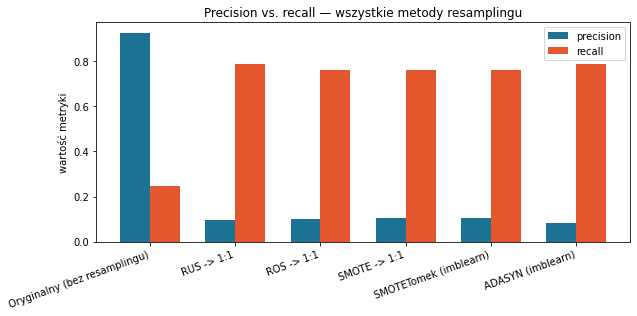

In [20]:
if IMBLEARN_OK:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    x = np.arange(len(wyniki_pelne_df))
    width = 0.35
    ax.bar(x - width/2, wyniki_pelne_df["precision"], width, label="precision", color="#1C7293")
    ax.bar(x + width/2, wyniki_pelne_df["recall"], width, label="recall", color="#E4572E")
    ax.set_xticks(x)
    ax.set_xticklabels(wyniki_pelne_df["metoda"], rotation=20, ha="right")
    ax.set_ylabel("wartość metryki")
    ax.set_title("Precision vs. recall — wszystkie metody resamplingu")
    ax.legend()
    plt.tight_layout()
    plt.show()